# Weeks 2 and 3 - Dataset Structuring and Validation

Directions: Before analytics begins, the dataset must be inspected and filtered to ensure only relevant residential
property records are used. This week also covers foundational EDA steps that inform every phase that
follows.

### Week 2
Create EDA Datasets and Reports using only residential property records.
Agenda:
- Understand the dataset (identify # of rows and cols, review column data types, identify columns with high # of missing values, and separate market analysis fields from metadata fields)
- Perform missing value analysis (calculate the missing counts and percentages per column, flag those with >90% missing vals, decide which ones should be dropped or retianed depending on how important they are despite the missing values)
- Numeric distribution review (for each key numeric field, generate histograms/boxplots/percentile summaries, and identify outliers)

In [1]:
import pandas as pd
from pathlib import Path
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
data_dir = Path("../data/processed_csv")

listing_path = data_dir / "listings_residential.csv"
sold_path = data_dir / "sold_residential.csv"

listing = pd.read_csv(listing_path, low_memory=False)
sold = pd.read_csv(sold_path, low_memory=False)

In [3]:
print("Listings shape:", listing.shape)
print("Sold shape:", sold.shape)

Listings shape: (547162, 84)
Sold shape: (414054, 84)


In [4]:
print("\nSold column data types:")
print(sold.dtypes)
print("\nListings column data types:")
print(listing.dtypes)


Sold column data types:
Flooring                       str
ViewYN                      object
WaterfrontYN                object
BasementYN                  object
PoolPrivateYN               object
                             ...  
lonfilled                   object
BuyerAgentAOR                  str
ListAgentAOR                   str
OriginatingSystemName          str
OriginatingSystemSubName       str
Length: 84, dtype: object

Listings column data types:
OriginalListPrice               float64
ListingKey                        int64
ListAgentEmail                      str
CloseDate                           str
ClosePrice                      float64
                                 ...   
BuyerOfficeName.1                   str
AssociationFee                  float64
LotSizeSquareFeet               float64
MiddleOrJuniorSchoolDistrict    float64
UnparsedAddress.1                   str
Length: 84, dtype: object


In [5]:
print("\nListings missing values:")
print(listing.isnull().sum())
print("\nSold missing values:")
print(sold.isnull().sum())


Listings missing values:
OriginalListPrice                  789
ListingKey                           0
ListAgentEmail                    1506
CloseDate                       388096
ClosePrice                      409481
                                 ...  
BuyerOfficeName.1               397275
AssociationFee                  132423
LotSizeSquareFeet                44350
MiddleOrJuniorSchoolDistrict    547162
UnparsedAddress.1                  783
Length: 84, dtype: int64

Sold missing values:
Flooring                    148589
ViewYN                       35264
WaterfrontYN                413795
BasementYN                  405952
PoolPrivateYN                35666
                             ...  
lonfilled                   305897
BuyerAgentAOR                62072
ListAgentAOR                 57379
OriginatingSystemName       369545
OriginatingSystemSubName    369545
Length: 84, dtype: int64


In [6]:
listing.head(10)

,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,...,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,BuyerOfficeName.1,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,UnparsedAddress.1
0,1340000.0,1074973329,haleh360@Gmail.com,NaN,NaN,Haleh,Dowlatshahi,34.052207,-118.408445,2220 Avenue Of The Stars 2704,...,NaN,False,NaN,NaN,90067,NaN,2105.00,177861.0,NaN,2220 Avenue Of The Stars 2704
1,2500000.0,1074954552,Reneechen@yourhomesoldguaranteed.com,NaN,NaN,Renee,Chen,33.496363,-117.691677,16 Palisades,...,0.0,False,3.0,Capistrano Unified,92677,NaN,254.00,5300.0,NaN,16 Palisades
2,3150000.0,1074936537,anader@dppre.com,NaN,NaN,Margaret,Nader,34.119345,-118.111254,1615 Waverly Road,...,NaN,NaN,2.0,NaN,91108,NaN,NaN,9404.0,NaN,1615 Waverly Road
3,3090000.0,1074917818,QIANYU0607@GMAIL.COM,NaN,NaN,QIANYU,GUAN,33.984057,-117.802819,2250 Indian Creek Road,...,1.0,False,4.0,Walnut Valley Unified,91765,NaN,295.95,58232.0,NaN,2250 Indian Creek Road
4,12725000.0,1074143166,jeff.williams@pacificsir.com,NaN,NaN,Jeff,Williams,33.607583,-117.887743,317 E. Bayfront,...,3.0,False,2.0,Newport Mesa Unified,92662,NaN,0.00,2250.0,NaN,317 E. Bayfront
5,665000.0,1073349180,BTRealtyGroup@gmail.com,NaN,NaN,Bryon,Thompson,32.929350,-116.945770,13281 Highway 67,...,3.0,False,0.0,Lakeside Union,92040,NaN,0.00,235224.0,NaN,13281 Highway 67
6,1125000.0,1073322022,tim@taylormaderealtor.com,NaN,NaN,Timothy,Taylor,33.761176,-116.419871,39540 Kirkwood Court,...,NaN,False,2.0,NaN,92270,NaN,NaN,10890.0,NaN,39540 Kirkwood Court
7,1849000.0,1073315828,heather.scherbert@gmail.com,NaN,NaN,Heather,Scherbert,34.206316,-118.221526,1994 Hilldale Drive,...,NaN,NaN,2.0,NaN,91011,NaN,NaN,6442.0,NaN,1994 Hilldale Drive
8,1389000.0,1073313770,homes@justinandjuhee.com,NaN,NaN,Justin and,Juhee Kim,33.862141,-117.723722,8715 E Foxhollow Dr,...,1.0,False,2.0,Orange Unified,92808,NaN,110.00,5076.0,NaN,8715 E Foxhollow Dr
9,1249888.0,1073295259,sandra.mcfetridge@gmail.com,2024-05-01,1262555.0,Sandra,McFetridge,33.477414,-117.664879,33450 Paseo El Lazo,...,0.0,False,2.0,Capistrano Unified,92675,Compass,395.00,NaN,NaN,33450 Paseo El Lazo


In [7]:
sold.head(10)

,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,...,PostalCode,AssociationFee,LotSizeSquareFeet,MiddleOrJuniorSchoolDistrict,latfilled,lonfilled,BuyerAgentAOR,ListAgentAOR,OriginatingSystemName,OriginatingSystemSubName
0,"Carpet,Tile,Wood",True,NaN,NaN,False,499000.0,551985747,jwachter@cbnorcal.com,2024-01-26,240000.0,...,94401,6472.0,NaN,NaN,True,True,NaN,NaN,NaN,NaN
1,NaN,False,NaN,NaN,False,759900.0,522107581,mdarwich12@gmail.com,2024-01-05,815000.0,...,91950,NaN,NaN,NaN,True,True,NaN,NaN,NaN,NaN
2,NaN,False,NaN,NaN,False,739900.0,510919001,mdarwich12@gmail.com,2024-01-05,810000.0,...,91950,NaN,NaN,NaN,True,True,NaN,NaN,NaN,NaN
3,NaN,True,NaN,NaN,False,2100000.0,1067652762,jenniferarielkennedy@gmail.com,2024-01-02,2100000.0,...,93401,0.0,11219.0,NaN,False,False,NaN,NaN,NaN,NaN
4,Tile,True,NaN,NaN,False,1950000.0,1063453216,kira@mendosir.com,2024-01-22,1950000.0,...,95437,NaN,74487.6,NaN,False,False,NaN,NaN,NaN,NaN
5,"Tile,Wood",True,NaN,NaN,NaN,NaN,1061988701,dannyduong@gmail.com,2024-01-31,2340000.0,...,95148,NaN,8712.0,NaN,True,True,NaN,NaN,NaN,NaN
6,"Stone,Wood",True,NaN,NaN,False,1550000.0,1061822266,MaxSellsSanDiego@gmail.com,2024-01-31,1485000.0,...,92101,2049.0,NaN,NaN,False,False,NaN,NaN,NaN,NaN
7,Wood,True,NaN,NaN,False,999000.0,1061617422,kerry.kimble@theagencyre.com,2024-01-30,1130000.0,...,90026,NaN,7128.0,NaN,False,False,NaN,NaN,NaN,NaN
8,Wood,True,NaN,NaN,False,1050000.0,1060223286,aliciao@kw.com,2024-01-16,1060000.0,...,90065,NaN,13029.0,NaN,False,False,NaN,NaN,NaN,NaN
9,NaN,False,NaN,NaN,NaN,NaN,1060105211,info@keyluxestates.com,2024-01-31,2150000.0,...,94030,NaN,6966.0,NaN,True,True,NaN,NaN,NaN,NaN


In [8]:
# double check property types to see if filter wa s correct
print("\nUnique Property Types in Sold:")
print(sold["PropertyType"].unique())
print("\nUnique Property Types in Listings:")
print(listing["PropertyType"].unique())


Unique Property Types in Sold:
<StringArray>
['Residential']
Length: 1, dtype: str

Unique Property Types in Listings:
<StringArray>
['Residential']
Length: 1, dtype: str


In [9]:
missing_count_listing = listing.isnull().sum()
missing_percent_listing = listing.isnull().sum() / len(listing) * 100
missing_report_listing = pd.DataFrame({
    "MissingCount": missing_count_listing,
    "MissingPercent": missing_percent_listing
})
missing_report_listing

,MissingCount,MissingPercent
OriginalListPrice,789,0.144199
ListingKey,0,0.000000
ListAgentEmail,1506,0.275238
CloseDate,388096,70.928902
ClosePrice,409481,74.837251
...,...,...
BuyerOfficeName.1,397275,72.606468
AssociationFee,132423,24.201790
LotSizeSquareFeet,44350,8.105461
MiddleOrJuniorSchoolDistrict,547162,100.000000


In [10]:
missing_count_sold = sold.isnull().sum()

missing_percent_sold = (sold.isnull().sum() / len(sold) * 100)

missing_report_sold = pd.DataFrame({
    "MissingCount": missing_count_sold,
    "MissingPercent": missing_percent_sold
})

missing_report_sold

,MissingCount,MissingPercent
Flooring,148589,35.886382
ViewYN,35264,8.516764
WaterfrontYN,413795,99.937448
BasementYN,405952,98.043250
PoolPrivateYN,35666,8.613852
...,...,...
lonfilled,305897,73.878528
BuyerAgentAOR,62072,14.991281
ListAgentAOR,57379,13.857854
OriginatingSystemName,369545,89.250436


Check for the columns now with over >90% Missing

In [11]:
missing_report_listing["Above90PercentMissing"] = (missing_report_listing["MissingPercent"] > 90)
missing_report_listing = missing_report_listing.sort_values("MissingPercent", ascending=False)

missing_report_listing.head(20)

,MissingCount,MissingPercent,Above90PercentMissing
TaxAnnualAmount,547162,100.000000,True
FireplacesTotal,547162,100.000000,True
ElementarySchoolDistrict,547162,100.000000,True
TaxYear,547162,100.000000,True
BusinessType,547162,100.000000,True
MiddleOrJuniorSchoolDistrict,547162,100.000000,True
CoveredSpaces,547162,100.000000,True
AboveGradeFinishedArea,547162,100.000000,True
BelowGradeFinishedArea,544075,99.435816,True
CoBuyerAgentFirstName,533466,97.496902,True


In [12]:
missing_report_sold["Above90PercentMissing"] = (missing_report_sold["MissingPercent"] > 90)
missing_report_sold = missing_report_sold.sort_values("MissingPercent", ascending=False)

missing_report_sold.head(20)

,MissingCount,MissingPercent,Above90PercentMissing
AboveGradeFinishedArea,414054,100.000000,True
CoveredSpaces,414054,100.000000,True
TaxAnnualAmount,414054,100.000000,True
TaxYear,414054,100.000000,True
ElementarySchoolDistrict,414054,100.000000,True
FireplacesTotal,414054,100.000000,True
MiddleOrJuniorSchoolDistrict,414054,100.000000,True
BusinessType,414054,100.000000,True
WaterfrontYN,413795,99.937448,True
BelowGradeFinishedArea,411652,99.419882,True


In [13]:
high_missing_listing = missing_report_listing[
    missing_report_listing["Above90PercentMissing"]
]

high_missing_listing.loc[missing_report_listing["Above90PercentMissing"]].index

Index(['TaxAnnualAmount', 'FireplacesTotal', 'ElementarySchoolDistrict',
       'TaxYear', 'BusinessType', 'MiddleOrJuniorSchoolDistrict',
       'CoveredSpaces', 'AboveGradeFinishedArea', 'BelowGradeFinishedArea',
       'CoBuyerAgentFirstName', 'BuilderName', 'LotSizeDimensions',
       'BuildingAreaTotal'],
      dtype='str')

In [14]:
high_missing_sold = missing_report_sold[
    missing_report_sold["Above90PercentMissing"]
]

missing_report_sold.loc[missing_report_sold["Above90PercentMissing"]].index

Index(['AboveGradeFinishedArea', 'CoveredSpaces', 'TaxAnnualAmount', 'TaxYear',
       'ElementarySchoolDistrict', 'FireplacesTotal',
       'MiddleOrJuniorSchoolDistrict', 'BusinessType', 'WaterfrontYN',
       'BelowGradeFinishedArea', 'BasementYN', 'LotSizeDimensions',
       'BuilderName', 'BuildingAreaTotal', 'CoBuyerAgentFirstName'],
      dtype='str')

Well now let's just remove everything with 100 percent missing values

In [15]:
fully_missing_listing = missing_report_listing[missing_report_listing["MissingPercent"] == 100].index.tolist()
fully_missing_listing

['TaxAnnualAmount',
 'FireplacesTotal',
 'ElementarySchoolDistrict',
 'TaxYear',
 'BusinessType',
 'MiddleOrJuniorSchoolDistrict',
 'CoveredSpaces',
 'AboveGradeFinishedArea']

In [16]:
fully_missing_sold = missing_report_sold[missing_report_sold["MissingPercent"] == 100].index.tolist()
fully_missing_sold

['AboveGradeFinishedArea',
 'CoveredSpaces',
 'TaxAnnualAmount',
 'TaxYear',
 'ElementarySchoolDistrict',
 'FireplacesTotal',
 'MiddleOrJuniorSchoolDistrict',
 'BusinessType']

In [17]:
sold_cleaned = sold.drop(columns=fully_missing_sold)
listing_cleaned = listing.drop(columns=fully_missing_listing)

In [18]:
sold_cleaned

,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,...,HighSchoolDistrict,PostalCode,AssociationFee,LotSizeSquareFeet,latfilled,lonfilled,BuyerAgentAOR,ListAgentAOR,OriginatingSystemName,OriginatingSystemSubName
0,"Carpet,Tile,Wood",True,NaN,NaN,False,499000.0,551985747,jwachter@cbnorcal.com,2024-01-26,240000.0,...,Other,94401,6472.0,NaN,True,True,NaN,NaN,NaN,NaN
1,NaN,False,NaN,NaN,False,759900.0,522107581,mdarwich12@gmail.com,2024-01-05,815000.0,...,NaN,91950,NaN,NaN,True,True,NaN,NaN,NaN,NaN
2,NaN,False,NaN,NaN,False,739900.0,510919001,mdarwich12@gmail.com,2024-01-05,810000.0,...,NaN,91950,NaN,NaN,True,True,NaN,NaN,NaN,NaN
3,NaN,True,NaN,NaN,False,2100000.0,1067652762,jenniferarielkennedy@gmail.com,2024-01-02,2100000.0,...,San Luis Coastal Unified,93401,0.0,11219.0,False,False,NaN,NaN,NaN,NaN
4,Tile,True,NaN,NaN,False,1950000.0,1063453216,kira@mendosir.com,2024-01-22,1950000.0,...,NaN,95437,NaN,74487.6,False,False,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
414049,NaN,True,NaN,True,False,279000.0,1069708148,jessica.homesells@gmail.com,2026-04-01,215000.0,...,Konocti Unified,95424,0.0,10019.0,NaN,NaN,LakeCounty,LakeCounty,CRMLS,CRMLS_CRM
414050,"Carpet,Tile,Wood",False,NaN,True,False,449000.0,1067010583,brian@cohen-realty.com,2026-04-13,415000.0,...,Rim of the World,92322,0.0,12096.0,NaN,NaN,TheInlandGateway,TheInlandGateway,CRMLS,CRMLS_CRM
414051,Vinyl,True,NaN,NaN,False,1579000.0,1063196193,info@homecoin.com,2026-04-16,1355000.0,...,Sanger Unified,93619,0.0,859874.4,NaN,NaN,SanDiego,TriCounties,CRMLS,CRMLS_CRM
414052,NaN,True,NaN,NaN,False,855000.0,1062106215,jefflachef@gmail.com,2026-04-16,820000.0,...,Capistrano Unified,92629,0.0,2733.0,NaN,NaN,Mrmls,OrangeCounty,CRMLS,CRMLS_CRM


In [19]:
listing_cleaned

,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,...,LotSizeArea,MainLevelBedrooms,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,BuyerOfficeName.1,AssociationFee,LotSizeSquareFeet,UnparsedAddress.1
0,1340000.0,1074973329,haleh360@Gmail.com,NaN,NaN,Haleh,Dowlatshahi,34.052207,-118.408445,2220 Avenue Of The Stars 2704,...,177861.00,NaN,False,NaN,NaN,90067,NaN,2105.00,177861.0,2220 Avenue Of The Stars 2704
1,2500000.0,1074954552,Reneechen@yourhomesoldguaranteed.com,NaN,NaN,Renee,Chen,33.496363,-117.691677,16 Palisades,...,5300.00,0.0,False,3.0,Capistrano Unified,92677,NaN,254.00,5300.0,16 Palisades
2,3150000.0,1074936537,anader@dppre.com,NaN,NaN,Margaret,Nader,34.119345,-118.111254,1615 Waverly Road,...,9404.00,NaN,NaN,2.0,NaN,91108,NaN,NaN,9404.0,1615 Waverly Road
3,3090000.0,1074917818,QIANYU0607@GMAIL.COM,NaN,NaN,QIANYU,GUAN,33.984057,-117.802819,2250 Indian Creek Road,...,58232.00,1.0,False,4.0,Walnut Valley Unified,91765,NaN,295.95,58232.0,2250 Indian Creek Road
4,12725000.0,1074143166,jeff.williams@pacificsir.com,NaN,NaN,Jeff,Williams,33.607583,-117.887743,317 E. Bayfront,...,2250.00,3.0,False,2.0,Newport Mesa Unified,92662,NaN,0.00,2250.0,317 E. Bayfront
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547157,2595000.0,1153444674,denny@dennykagasoff.com,NaN,NaN,Denny,Kagasoff,34.129724,-118.394741,12004 Briarvale Lane,...,24226.00,NaN,False,NaN,NaN,91604,NaN,NaN,24226.0,12004 Briarvale Lane
547158,7285000.0,1152609167,ann@brizolisjanzen.com,NaN,NaN,K. Ann,Brizolis,32.980315,-117.198367,14480 Bellvista Dr,...,NaN,NaN,False,3.0,NaN,92067,NaN,735.00,NaN,14480 Bellvista Dr
547159,396000.0,1151471220,jason@venture-pacific.net,NaN,NaN,Jason,Lipovsky,33.002752,-116.782659,15755 Davis Cup Lane,...,19.09,1.0,NaN,0.0,Ramona Unified,92065,NaN,596.00,831560.4,15755 Davis Cup Lane
547160,985000.0,1149517845,aisaethan@icloud.com,NaN,NaN,Aisa,Tu,33.645255,-117.358172,33115 Evergreen Sreet,...,14810.00,2.0,NaN,3.0,Lake Elsinore Unified,92530,NaN,0.00,14810.0,33115 Evergreen Sreet


In [20]:
core_fields = [
    "PropertyType",
    "ClosePrice",
    "OriginalListPrice",
    "ListPrice",
    "LivingArea",
    "LotSizeAcres",
    "BedroomsTotal",
    "CountyOrParish",
    "BathroomsTotalInteger",
    "DaysOnMarket",
    "YearBuilt",
    "CloseDate",
    "ListingContractDate"
]

numeric_fields = [
    "ClosePrice",
    "ListPrice",
    "OriginalListPrice",
    "LivingArea",
    "LotSizeAcres",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "DaysOnMarket",
    "YearBuilt"
]

market_fields = [
    "ClosePrice",
    "ListPrice",
    "OriginalListPrice",
    "LivingArea",
    "LotSizeAcres",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "DaysOnMarket",
    "YearBuilt",
    "CloseDate",
    "ListingContractDate",
    "CountyOrParish",
    "PropertyType"
]

In [21]:
numeric_summary = sold_cleaned[numeric_fields].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.99]).T
numeric_summary

,count,mean,std,min,1%,5%,25%,50%,75%,99%,max
ClosePrice,414052.0,1.193864e+06,6.290122e+06,0.0,202302.0,340000.00,575000.00,823000.0000,1300000.000,5.575000e+06,9.895000e+08
ListPrice,414054.0,1.140462e+06,1.359497e+06,525.0,214900.0,347000.00,576167.00,815000.0000,1295000.000,5.700000e+06,1.375000e+08
OriginalListPrice,413298.0,1.225401e+06,6.709938e+06,0.0,210000.0,349900.00,585000.00,825000.0000,1299000.000,5.995000e+06,1.390000e+09
LivingArea,413820.0,1.903791e+03,2.647620e+04,0.0,604.0,840.00,1248.00,1642.0000,2219.000,5.282000e+03,1.702132e+07
LotSizeAcres,381519.0,6.630318e+01,1.599818e+04,0.0,0.0,0.03,0.12,0.1664,0.273,1.083350e+01,7.810698e+06
BedroomsTotal,414043.0,3.201056e+00,1.067103e+00,0.0,1.0,2.00,3.00,3.0000,4.000,6.000000e+00,4.500000e+01
BathroomsTotalInteger,413985.0,2.534771e+00,1.134152e+00,0.0,1.0,1.00,2.00,2.0000,3.000,6.000000e+00,1.750000e+02
DaysOnMarket,414054.0,3.735512e+01,5.359246e+01,-288.0,0.0,1.00,8.00,18.0000,48.000,2.310000e+02,1.243000e+04
YearBuilt,413682.0,1.978580e+03,2.627823e+01,1776.0,1912.0,1930.00,1960.00,1979.0000,1999.000,2.025000e+03,2.026000e+03


In [22]:
deliverable_fields = [
    "ClosePrice",
    "LivingArea",
    "DaysOnMarket"
]

deliverable_summary = pd.DataFrame({
    "min": sold_cleaned[deliverable_fields].min(),
    "max": sold_cleaned[deliverable_fields].max(),
    "mean": sold_cleaned[deliverable_fields].mean(),
    "med": sold_cleaned[deliverable_fields].median(),
    "25th percentile": sold_cleaned[deliverable_fields].quantile(0.25),
    "75th percentile": sold_cleaned[deliverable_fields].quantile(0.75),
    "95th percentile": sold_cleaned[deliverable_fields].quantile(0.95),
    "99th percentile": sold_cleaned[deliverable_fields].quantile(0.99)
})

deliverable_summary

,min,max,mean,med,25th percentile,75th percentile,95th percentile,99th percentile
ClosePrice,0.0,989500000.0,1.193864e+06,823000.0,575000.0,1300000.0,2850000.00,5575000.0
LivingArea,0.0,17021321.0,1.903791e+03,1642.0,1248.0,2219.0,3559.05,5282.0
DaysOnMarket,-288.0,12430.0,3.735512e+01,18.0,8.0,48.0,132.00,231.0


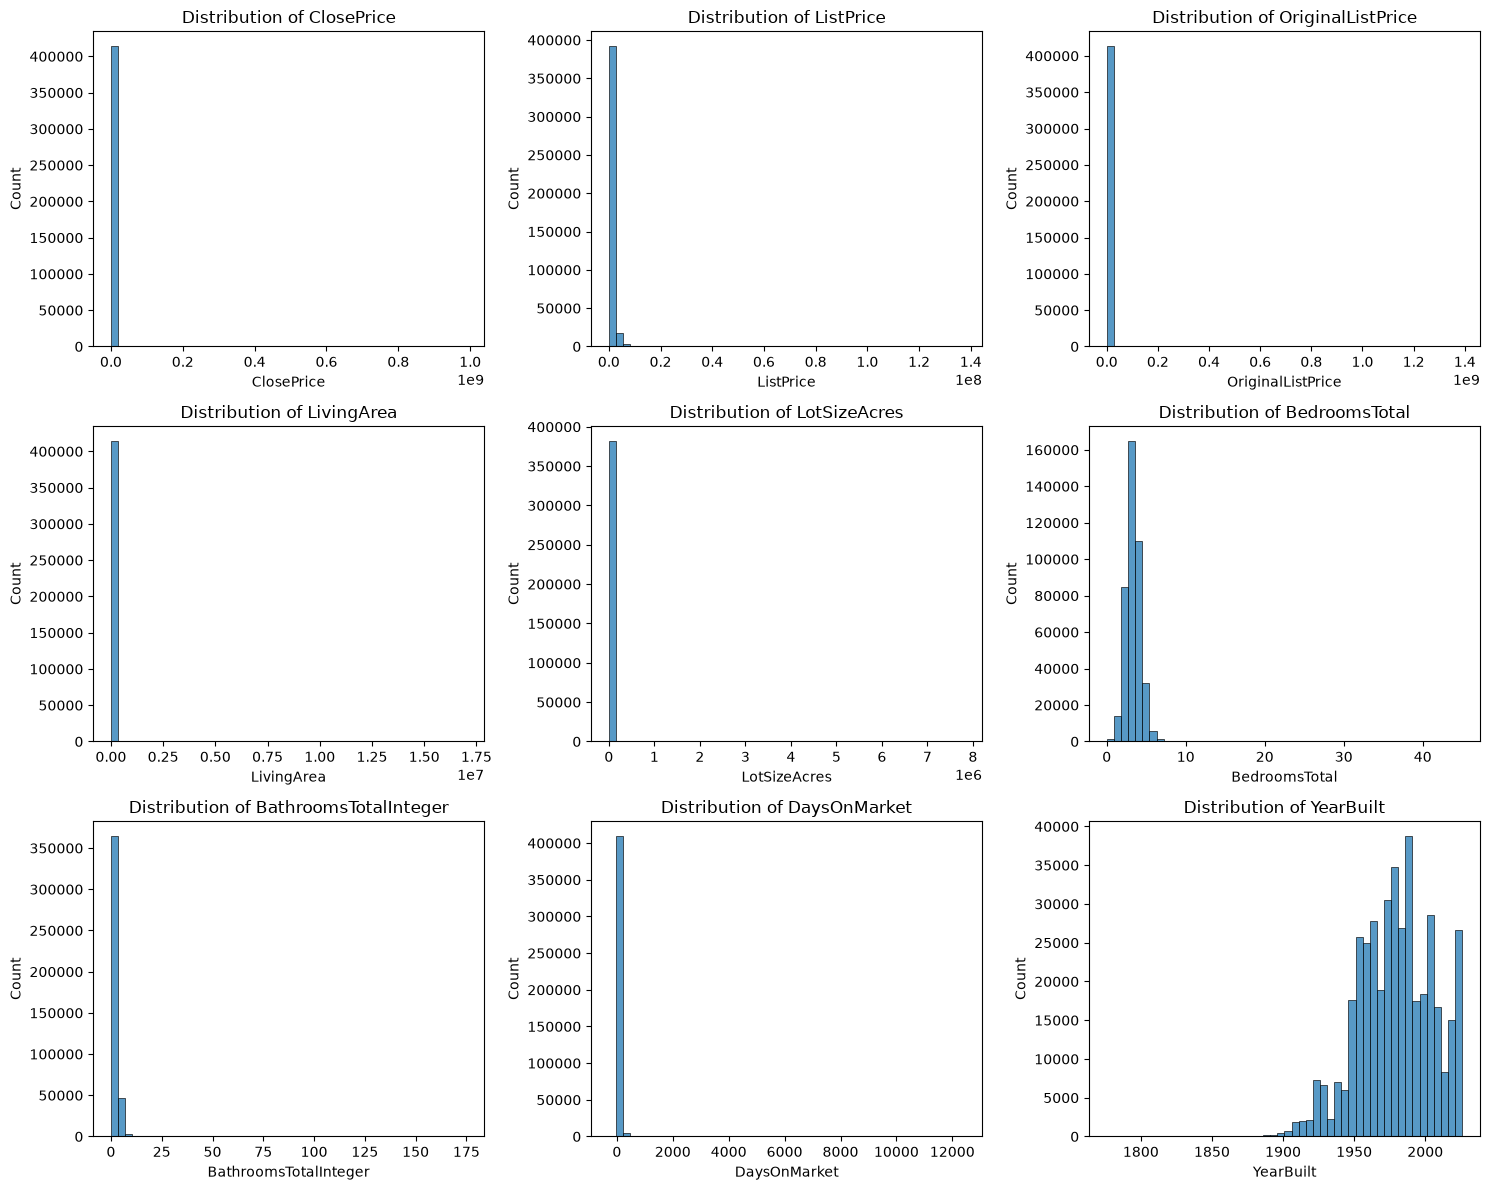

In [23]:
import math
n_cols = 3
n_rows = math.ceil(len(numeric_fields) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))

axes = axes.flatten()

for i, column in enumerate(numeric_fields):
    sns.histplot(
        data=sold_cleaned,
        x=column,
        bins=50,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Count")

# remove empty plots
for i in range(len(numeric_fields), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

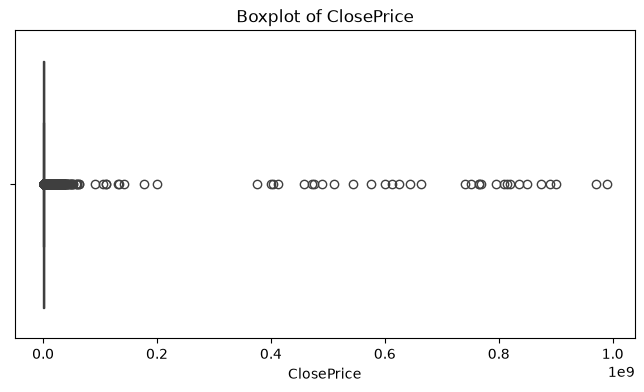

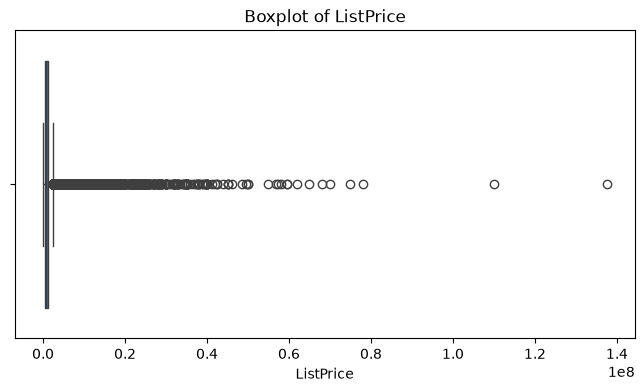

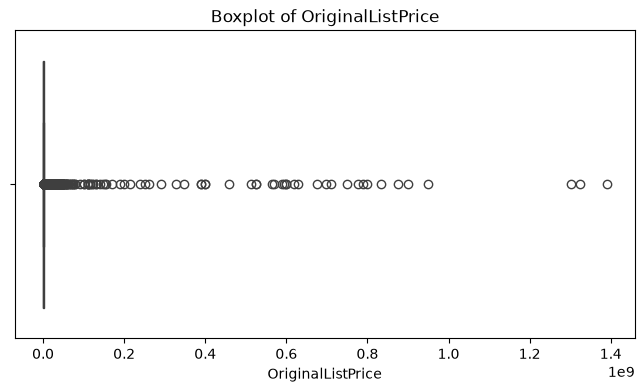

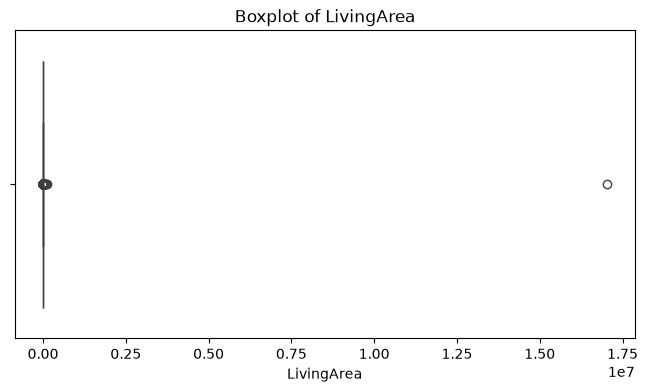

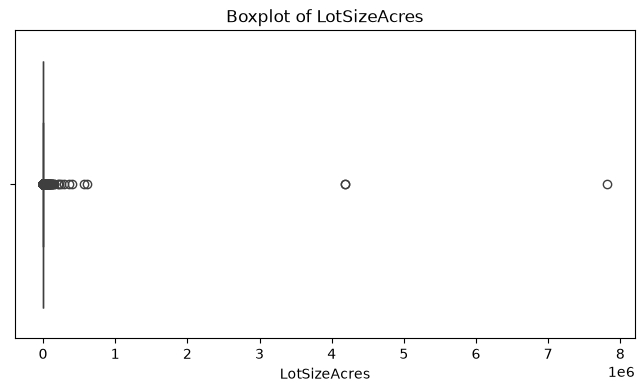

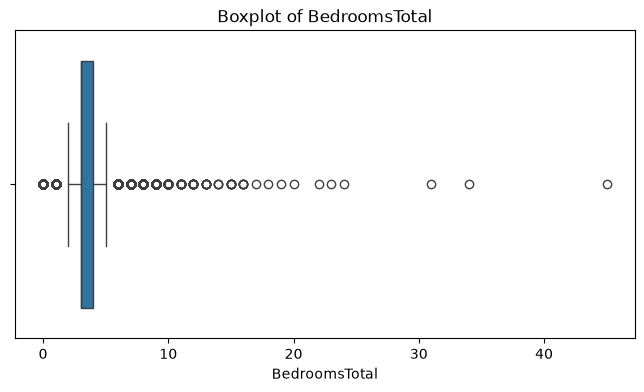

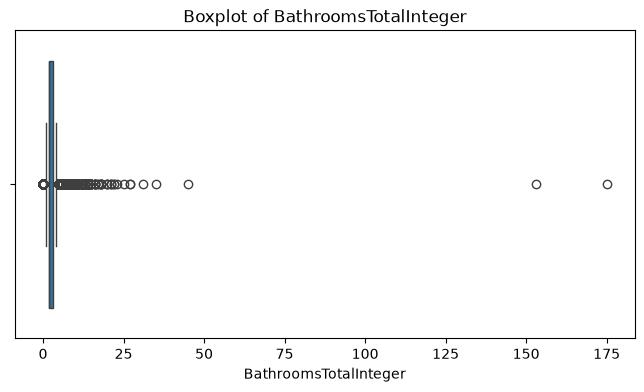

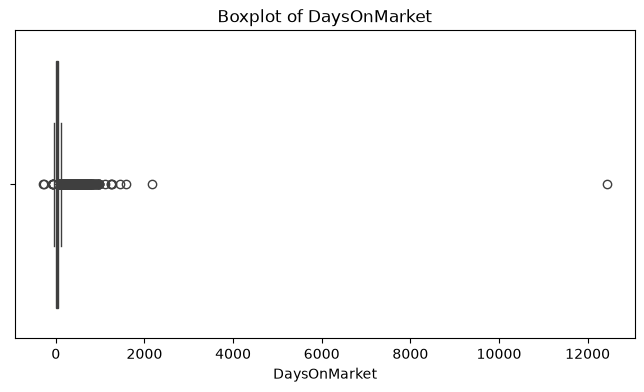

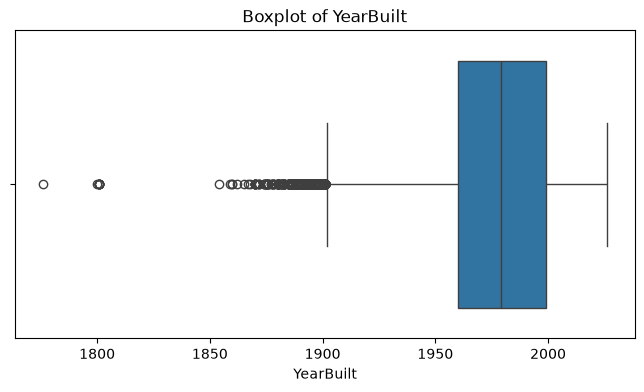

In [24]:
for column in numeric_fields:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=sold_cleaned,
        x=column
    )

    plt.title(f"Boxplot of {column}")
    plt.show()

There are an insane number of outliers I don't know if that's just me though lol

In [25]:
# create new report directory and save missing report and deliverable summary to just keep in local files

report_dir = Path("../data/reports")
report_dir.mkdir(exist_ok=True)

missing_report_sold.to_csv(
    report_dir / "sold_missing_report.csv"
)

missing_report_listing.to_csv(
    report_dir / "listing_missing_report.csv"
)

numeric_summary.to_csv(
    report_dir / "sold_numeric_summary.csv"
)

sold.to_csv(
    data_dir / "sold_residential_validated.csv",
    index=False
)


# also add the cleaned datasets just to keep things organized
cleaned_dir = Path("../data/cleaned_csv")
cleaned_dir.mkdir(exist_ok=True)

sold_cleaned.to_csv(
    cleaned_dir / "sold_residential_cleaned.csv",
    index=False
)

listing_cleaned.to_csv(
    cleaned_dir / "listings_residential_cleaned.csv",
    index=False
)

# Week 3 - FRED Monthly Mortgage Rates Merge
Enrich both the combined sold and listings datasets by merging in the national 30-year fixed mortgage
rate from the St. Louis Federal Reserve (FRED). This introduces interns to fetching live economic data
from a public API and performing a time-series join on a monthly key.

Fetch the "FRED MORTGAGE30US" series, resample it from weekly to monthly frequency, and merge it
onto both combined datasets using a year-month key derived from transaction dates.

### Step 1 - Fetch the mortgage rate data from FRED

In [26]:
import pandas as pd
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MORTGAGE30US"
mortgage = pd.read_csv(url, parse_dates=['observation_date'])
mortgage.columns = ['date', 'rate_30yr_fixed']

In [27]:
mortgage

,date,rate_30yr_fixed
0,1971-04-02,7.33
1,1971-04-09,7.31
2,1971-04-16,7.31
3,1971-04-23,7.31
4,1971-04-30,7.29
...,...,...
2895,2026-09-24,7.03
2896,2026-10-01,7.28
2897,2026-10-08,7.40
2898,2026-10-15,7.40


In [28]:
print(mortgage["date"].max())
print(mortgage["date"].min())
mortgage.dtypes

2026-10-22 00:00:00
1971-04-02 00:00:00


date               datetime64[us]
rate_30yr_fixed           float64
dtype: object

### Step 2 – Resample weekly rates to monthly averages

In [29]:
mortgage['year_month'] = mortgage['date'].dt.to_period('M')
mortgage_monthly = (
    mortgage
    .groupby("year_month")["rate_30yr_fixed"]
    .mean()
    .reset_index()
)

mortgage_monthly

,year_month,rate_30yr_fixed
0,1971-04,7.3100
1,1971-05,7.4250
2,1971-06,7.5300
3,1971-07,7.6040
4,1971-08,7.6975
...,...,...
662,2026-06,6.4900
663,2026-07,6.5420
664,2026-08,6.6675
665,2026-09,6.8625


### Step 3 – Clean the dates

In [30]:
print("Cleaned listings shape:", listing_cleaned.shape)
print("Cleaned sold shape:", sold_cleaned.shape)

Cleaned listings shape: (547162, 76)
Cleaned sold shape: (414054, 76)


In [31]:
sold_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 414054 entries, 0 to 414053
Data columns (total 76 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Flooring                     265465 non-null  str    
 1   ViewYN                       378790 non-null  object 
 2   WaterfrontYN                 259 non-null     object 
 3   BasementYN                   8102 non-null    object 
 4   PoolPrivateYN                378388 non-null  object 
 5   OriginalListPrice            413298 non-null  float64
 6   ListingKey                   414054 non-null  int64  
 7   ListAgentEmail               412989 non-null  str    
 8   CloseDate                    414054 non-null  str    
 9   ClosePrice                   414052 non-null  float64
 10  ListAgentFirstName           410945 non-null  str    
 11  ListAgentLastName            414012 non-null  str    
 12  Latitude                     409950 non-null  float64
 13  Longitude 

In [32]:
listing_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 547162 entries, 0 to 547161
Data columns (total 76 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   OriginalListPrice            546373 non-null  float64
 1   ListingKey                   547162 non-null  int64  
 2   ListAgentEmail               545656 non-null  str    
 3   CloseDate                    159066 non-null  str    
 4   ClosePrice                   137681 non-null  float64
 5   ListAgentFirstName           542808 non-null  str    
 6   ListAgentLastName            547120 non-null  str    
 7   Latitude                     466915 non-null  float64
 8   Longitude                    466915 non-null  float64
 9   UnparsedAddress              546380 non-null  str    
 10  PropertyType                 547162 non-null  str    
 11  LivingArea                   546610 non-null  float64
 12  ListPrice                    547162 non-null  float64
 13  DaysOnMark

In [33]:
sold_cleaned["CloseDate"] = pd.to_datetime(
    sold_cleaned["CloseDate"],
    errors="coerce"
)

listing_cleaned["ListingContractDate"] = pd.to_datetime(
    listing_cleaned["ListingContractDate"],
    errors="coerce"
)

print(sold_cleaned["CloseDate"].head())
print(listing_cleaned["ListingContractDate"].head())

0   2024-01-26
1   2024-01-05
2   2024-01-05
3   2024-01-02
4   2024-01-22
Name: CloseDate, dtype: datetime64[us]
0   2024-01-01
1   2024-01-24
2   2024-01-12
3   2024-01-20
4   2024-01-12
Name: ListingContractDate, dtype: datetime64[us]


In [34]:
sold_cleaned["year_month"] = (
    sold_cleaned["CloseDate"]
    .dt.to_period("M")
)

listing_cleaned["year_month"] = (
    listing_cleaned["ListingContractDate"]
    .dt.to_period("M")
)

sold_cleaned[["CloseDate", "year_month"]].head()

,CloseDate,year_month
0,2024-01-26,2024-01
1,2024-01-05,2024-01
2,2024-01-05,2024-01
3,2024-01-02,2024-01
4,2024-01-22,2024-01


In [35]:
listing_cleaned[["ListingContractDate", "year_month"]].head()

,ListingContractDate,year_month
0,2024-01-01,2024-01
1,2024-01-24,2024-01
2,2024-01-12,2024-01
3,2024-01-20,2024-01
4,2024-01-12,2024-01


### Step 4 - Merge the mortgage rates to sold

In [36]:
sold_with_rates = sold_cleaned.merge(mortgage_monthly, on="year_month", how="left")
print(len(sold_cleaned) == len(sold_with_rates))

listing_with_rates = listing_cleaned.merge(mortgage_monthly, on="year_month", how="left")
print(len(listing_cleaned) == len(listing_with_rates))

True
True


In [37]:
sold_with_rates

,Flooring,ViewYN,WaterfrontYN,BasementYN,PoolPrivateYN,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,...,AssociationFee,LotSizeSquareFeet,latfilled,lonfilled,BuyerAgentAOR,ListAgentAOR,OriginatingSystemName,OriginatingSystemSubName,year_month,rate_30yr_fixed
0,"Carpet,Tile,Wood",True,NaN,NaN,False,499000.0,551985747,jwachter@cbnorcal.com,2024-01-26,240000.0,...,6472.0,NaN,True,True,NaN,NaN,NaN,NaN,2024-01,6.6425
1,NaN,False,NaN,NaN,False,759900.0,522107581,mdarwich12@gmail.com,2024-01-05,815000.0,...,NaN,NaN,True,True,NaN,NaN,NaN,NaN,2024-01,6.6425
2,NaN,False,NaN,NaN,False,739900.0,510919001,mdarwich12@gmail.com,2024-01-05,810000.0,...,NaN,NaN,True,True,NaN,NaN,NaN,NaN,2024-01,6.6425
3,NaN,True,NaN,NaN,False,2100000.0,1067652762,jenniferarielkennedy@gmail.com,2024-01-02,2100000.0,...,0.0,11219.0,False,False,NaN,NaN,NaN,NaN,2024-01,6.6425
4,Tile,True,NaN,NaN,False,1950000.0,1063453216,kira@mendosir.com,2024-01-22,1950000.0,...,NaN,74487.6,False,False,NaN,NaN,NaN,NaN,2024-01,6.6425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
414049,NaN,True,NaN,True,False,279000.0,1069708148,jessica.homesells@gmail.com,2026-04-01,215000.0,...,0.0,10019.0,NaN,NaN,LakeCounty,LakeCounty,CRMLS,CRMLS_CRM,2026-04,6.3320
414050,"Carpet,Tile,Wood",False,NaN,True,False,449000.0,1067010583,brian@cohen-realty.com,2026-04-13,415000.0,...,0.0,12096.0,NaN,NaN,TheInlandGateway,TheInlandGateway,CRMLS,CRMLS_CRM,2026-04,6.3320
414051,Vinyl,True,NaN,NaN,False,1579000.0,1063196193,info@homecoin.com,2026-04-16,1355000.0,...,0.0,859874.4,NaN,NaN,SanDiego,TriCounties,CRMLS,CRMLS_CRM,2026-04,6.3320
414052,NaN,True,NaN,NaN,False,855000.0,1062106215,jefflachef@gmail.com,2026-04-16,820000.0,...,0.0,2733.0,NaN,NaN,Mrmls,OrangeCounty,CRMLS,CRMLS_CRM,2026-04,6.3320


In [38]:
listing_with_rates

,OriginalListPrice,ListingKey,ListAgentEmail,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,...,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,BuyerOfficeName.1,AssociationFee,LotSizeSquareFeet,UnparsedAddress.1,year_month,rate_30yr_fixed
0,1340000.0,1074973329,haleh360@Gmail.com,NaN,NaN,Haleh,Dowlatshahi,34.052207,-118.408445,2220 Avenue Of The Stars 2704,...,False,NaN,NaN,90067,NaN,2105.00,177861.0,2220 Avenue Of The Stars 2704,2024-01,6.6425
1,2500000.0,1074954552,Reneechen@yourhomesoldguaranteed.com,NaN,NaN,Renee,Chen,33.496363,-117.691677,16 Palisades,...,False,3.0,Capistrano Unified,92677,NaN,254.00,5300.0,16 Palisades,2024-01,6.6425
2,3150000.0,1074936537,anader@dppre.com,NaN,NaN,Margaret,Nader,34.119345,-118.111254,1615 Waverly Road,...,NaN,2.0,NaN,91108,NaN,NaN,9404.0,1615 Waverly Road,2024-01,6.6425
3,3090000.0,1074917818,QIANYU0607@GMAIL.COM,NaN,NaN,QIANYU,GUAN,33.984057,-117.802819,2250 Indian Creek Road,...,False,4.0,Walnut Valley Unified,91765,NaN,295.95,58232.0,2250 Indian Creek Road,2024-01,6.6425
4,12725000.0,1074143166,jeff.williams@pacificsir.com,NaN,NaN,Jeff,Williams,33.607583,-117.887743,317 E. Bayfront,...,False,2.0,Newport Mesa Unified,92662,NaN,0.00,2250.0,317 E. Bayfront,2024-01,6.6425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
547157,2595000.0,1153444674,denny@dennykagasoff.com,NaN,NaN,Denny,Kagasoff,34.129724,-118.394741,12004 Briarvale Lane,...,False,NaN,NaN,91604,NaN,NaN,24226.0,12004 Briarvale Lane,2026-04,6.3320
547158,7285000.0,1152609167,ann@brizolisjanzen.com,NaN,NaN,K. Ann,Brizolis,32.980315,-117.198367,14480 Bellvista Dr,...,False,3.0,NaN,92067,NaN,735.00,NaN,14480 Bellvista Dr,2026-04,6.3320
547159,396000.0,1151471220,jason@venture-pacific.net,NaN,NaN,Jason,Lipovsky,33.002752,-116.782659,15755 Davis Cup Lane,...,NaN,0.0,Ramona Unified,92065,NaN,596.00,831560.4,15755 Davis Cup Lane,2026-04,6.3320
547160,985000.0,1149517845,aisaethan@icloud.com,NaN,NaN,Aisa,Tu,33.645255,-117.358172,33115 Evergreen Sreet,...,NaN,3.0,Lake Elsinore Unified,92530,NaN,0.00,14810.0,33115 Evergreen Sreet,2026-04,6.3320


In [39]:
sold_with_rates[["CloseDate","year_month","ClosePrice","rate_30yr_fixed"]].head(10)

,CloseDate,year_month,ClosePrice,rate_30yr_fixed
0,2024-01-26,2024-01,240000.0,6.6425
1,2024-01-05,2024-01,815000.0,6.6425
2,2024-01-05,2024-01,810000.0,6.6425
3,2024-01-02,2024-01,2100000.0,6.6425
4,2024-01-22,2024-01,1950000.0,6.6425
5,2024-01-31,2024-01,2340000.0,6.6425
6,2024-01-31,2024-01,1485000.0,6.6425
7,2024-01-30,2024-01,1130000.0,6.6425
8,2024-01-16,2024-01,1060000.0,6.6425
9,2024-01-31,2024-01,2150000.0,6.6425


In [40]:
listing_with_rates[["ListingContractDate","year_month","ListPrice","rate_30yr_fixed"]].head(10)

,ListingContractDate,year_month,ListPrice,rate_30yr_fixed
0,2024-01-01,2024-01,1340000.0,6.6425
1,2024-01-24,2024-01,2500000.0,6.6425
2,2024-01-12,2024-01,3150000.0,6.6425
3,2024-01-20,2024-01,3090000.0,6.6425
4,2024-01-12,2024-01,12725000.0,6.6425
5,2024-01-30,2024-01,665000.0,6.6425
6,2024-01-26,2024-01,1125000.0,6.6425
7,2024-01-08,2024-01,1849000.0,6.6425
8,2024-01-25,2024-01,1389000.0,6.6425
9,2024-01-29,2024-01,1249888.0,6.6425


In [41]:
# save to cleaned csv
cleaned_dir = Path("../data/cleaned_csv")
cleaned_dir.mkdir(exist_ok=True)

sold_with_rates.to_csv(
    cleaned_dir / "sold_residential_with_rates.csv",
    index=False
)

listing_with_rates.to_csv(
    cleaned_dir / "listings_residential_with_rates.csv",
    index=False
)

### EDA Questions
- What is the Residential vs. other property type share?
- What are the median and average close prices?
- What does the Days on Market distribution look like?
- What percentage of homes sold above vs. below list price?
- Are there any apparent date consistency issues (e.g., close date before listing date)?
- Which counties have the highest median prices?